# Neural Networks for Molecular HOMO/LUMO Energy Prediction
## A first-principles tutorial and graded homework (100 points)

Prof. Victor S. Batista

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

An earlier version of this assignment was initially desiged by Dr. Jessica Freeze



**Scientific question:** Can measured or computed substituent descriptors predict the energies of frontier orbitals of tungsten–benzylidyne complexes without calculating every candidate from scratch?

**Audience:** Chemistry students with no prior machine-learning experience. **Platform:** Google Colab (CPU is sufficient) or local Jupyter with NumPy, pandas, matplotlib, scikit-learn and PyTorch.

**Learning goals:** interpret chemical descriptors; distinguish identifiers/features/targets; build a two-hidden-layer neural network; understand weights, biases, activation functions, and gradients; use training/validation/test data correctly; evaluate orbital-energy predictions; compare against a linear baseline; quantify variation across random initializations; extract a trained scoring function.

**What to submit:** one executed `.ipynb` with your written answers in the indicated response cells, labeled plots and tables, and a short concluding scientific interpretation. The example answers are deliberately **not** supplied for graded prompts.

**Ethical/scientific note:** Hammett constants for these coordination environments are approximations. The data supplied here are the example's computed quantities, not independent experimental validation. A strong test score on this 150-member library does not establish transferability to other catalyst families.

## Roadmap and grading

| Student task | Required evidence | Points |
|---|---|---:|
| 1. Chemical data and feature interpretation | Identify variables; inspect 30/120 split; explain descriptor approximation | 15 |
| 2. Neural-network mathematics | Worked forward pass; dimensions and bias/activation explanations | 20 |
| 3. Training and learning curves | Training/validation plots; epoch and overfitting interpretation | 20 |
| 4. Evaluation and baseline | Test MAE/RMSE/R², parity plot, linear baseline and interpretation | 20 |
| 5. Model sensitivity and screening | Three seeds, rankings, uncertainty discussion | 15 |
| 6. Extract scoring function and reflect | Verify manual forward pass; propose new chemical application | 10 |
| **Total** | | **100** |

**Grading principles:** roughly half the marks reward scientific reasoning and reproducibility rather than simply obtaining a small numerical error. Every graph needs labeled axes and units. State the seed and split used. There is no required target accuracy, because a small dataset produces seed-dependent results.

## Part 1. The chemistry and the dataset

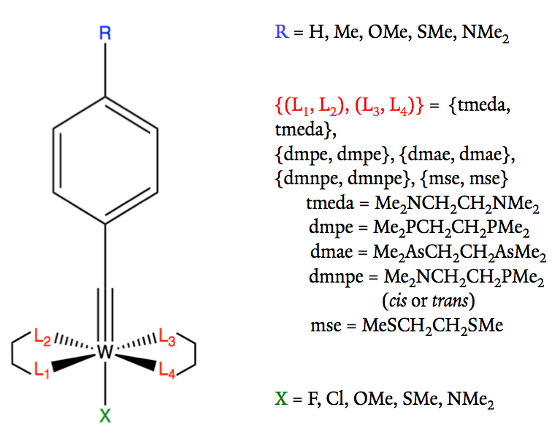

The original case study varies the **R** substituent, ligand environment **L**, and **X** substituent around tungsten. Its library contains 150 candidate complexes, with 30 selected for model development and 120 reserved as a test set. The original assignment uses *Hammett-style substituent constants* as a compact numerical description of electronic substituent effects. In organic aromatic chemistry, σ values summarize how substituents influence a reference reaction; extending them to donor ligands in tungsten complexes is a chemical **approximation**, not an exact physical identity.

A row in the CSV represents **one candidate molecule**. The thirteen columns contain:

- column 0: a three-digit molecular code (**identifier**, never an input feature);
- columns 1–10: **ten input features** (five pairs of meta/para Hammett-style constants for R, L1, L2, L3, and X);
- columns 11–12: two predicted **targets** for learning: DFT-derived \(d_{xy}\)-related orbital energy and \(d_{xy}\)–LUMO gap (in eV, as represented in the original assignment).

A **feature** is information supplied to the model; a **target** is the numerical answer it tries to learn. **Regression** means predicting continuous values (such as eV), not predicting chemical class labels. A molecular ID is useful for looking up molecules but has no numerical physical meaning.

### Worked example: features are not labels

For a hypothetical row `[111, 0.0, 0.0, ..., 0.34, 0.06, -2.52, 2.47]`, `111` identifies the complex; ten intervening numbers describe it; the last two are the labels we wish to predict. Learning from the ID would encode arbitrary bookkeeping rather than chemistry.

**Why reserve test molecules?** A student preparing for an exam should practice with examples *not* identical to the exam questions. A model likewise needs new molecules to check whether it has learned transferable relationships instead of memorizing the 30 training examples. Here the 120 held-out labels are available for the course exercise, but they must never be used to choose model settings.

In [ ]:
# 1. Load all three supplied datasets without Google Drive paths.
# If original CSV files are next to this notebook, use them directly.
# Otherwise the compressed originals embedded below make this notebook self-contained.
import io, gzip, base64, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EMBEDDED = {'HammettNNTrain.csv': 'H4sIABHU5GoC/42VC5KjMAxET6CbEMr6Wfb9L7Yt2ITPYCeTGkIFqyW/ljAzLwWfV1lF8xoyvC+rGi6lLi9ZXRZZrbp0YpFNo6yc//p4o7HsUpYCumqxMGLV/6G7xu2L9wJieenaHVEmwUho9k7YsiAd3XnuzFIGCU0aErr/2e/fcvE717w2zdTWsNdmGkhdeRw/gIXcFQK99dJJ9j2V2JLEr+Df9AA+oKXG1kj2FR+tqQEXlgYgXqCAIq8Kzz5sIBGniGPkDhLze+6JFzeg0aEjoR08nIc8HvvooJoNUWpzJ6nyXWRAVPMW9ga7kd5Q/WTOsRzGdGjV6AYtsfPDuTlvwGkMAlVJ1a/hD87csLa0R/HHhAa5JZ9OyocqpjOHpVp4J3UZ0ZiOOCYmDS4eNUirfhUZ8USTZMMpoeU+lH7zZFuKacnJE4YhZOLvBxMvbkh7FiAlDDUoH/GPY3Lqzd3IXrmSmZzyzm04XpIoWfr2xpMiZK5P+/8255ZVFCnMZNWmCk/4shWBL7ipk7Nf4fzgw2U9hoPzzOjZny58eTo/O05c8+yICOzIVW4Sz6YcXdk5X3teQslN7/nnR8mJassaaisCKG5DKLM5tzwPOg4j8urfFYZMNRVhMeM4/QcQ/hkyywcAAA==', 'HammettNNTest.csv': 'H4sIABHU5GoC/52Zz24cNwzGn2DfwUCuzkL8K+leoJcUBQoUyDWHoKcWQdBD8/b9yNnxzoyzHskI4own5m9FiuJHyh+e6Pr0x6fPlw9PjIe/v/77BY+Cx29fvsejXp8+0e21xfPtveOZb+9rPN/eNzzL7X2P5+U9levT5+U14RM/397iM3/578fT13++fv/rB76X/P7jpz9/+/3p1y/f1v8g4ueCPx/LlSW+Vn74XK5Sn5fv+epFiz/zVYo1BUYmMLS8qMFRqQ0YdWsMjM5gLH6Ur+bkBAbVbg0MG2bgK3l8bemT1qIGEJuSXIgpQfiZ+Cs/fRAs+IpAfNRr0abPAk9aeMJybnyPg1y740PTXKnDXAfM03+YdqEKU/LqsLQzy53XMGcO41YNnyurz8w/+efFW1hZqWEnja3Cjt+0W/MGUSoZJZZWwkzfMntx0DoescZSJNZoj40OvrVGvYWl1lilvuxoC0fkwdN2U6tHaNVMkVrKY/Z3d7kgsAFAasNehux3eWE97TnDrDYAOMaAuHqGXBtdyOjV8XgzseVq7BH9wrXiVBiP2a8xgD0WH2e81cpIUJMhwDYIaosLhZhxtkzHCLf0MUKu4fOrdKzf31j/g2qHLI90DxcYf8CQUcbWC4TRorz0ml64DkNujoiyRc2tcChWYWOAQz5gGzmWUXtsBxPFf8G7+LE6KgRrdqBoNuuxKEUFq8DJO3A7QcCJSUXorB08fQ9vVQauKEwo6EiZYNk066gQokg+AOE0nOV97IaVIjbyORKzJ4UnKJtKquw9KrB5h3Os45S7cixFnLoCYKOAY4HpzVoWGEOBYDkG5VRKRFqEQwVbD3sesr8fzl47RyC4CRvsZcR+V2N5VW5DHMTO7Y8R0J5RJEgo66ukGBYbJEQsxEpxnEzlOdA9NajWLukRKiZAMgXahQb6niCqCK3qHCjTDH611i17BXdQjB8ewzMloeh0UEGZGiJtMgXaKQq7hK4WrQ1H0HSOdDs/qFEc9aU2QnvAZhOUQwqpQVQgMIgUXdjpnPSgIiPMIkVSsK0ES2ZZO9GSTim9BTkAmE7DVvGibPSriSK33eY4Rw3DEdHU43BRiHarnpYw1K0OmqOAKGj8Dtp9MjLJndTKHSydZ63qpWjsY8IyhB4kmyUdtEu65+HREp2+8C5mw9JFRWJMca8UEB6HbJSLoyHMOicNEBmG7EoTSc2lWGmID9sg5dWIgIEtixMVbL4cwnIqXtQka3bj2G/hEfONdnmeLhVGR4eDO2C9jUHrVTKSTiKw1xH7VfzRTKZs58AqetzKYbHR7GXQTRooMkPZb2crnoHMpFCdAq1KE3NaxFO5gmHjjENWVF8kSwu6q4vYwwJzMjstVwoIctEGr0xmODvBKrEINBnQK8TZdAq06pW7R9nsRRXxMRuHHOWKY5aJiayj6xc/j89DueK+yBVhgkAOO8+iNmMaotRSrGpBkFwnUWucuBULXW9eI05uU5yjVhF5Ni3SC1900Sobv3O765ShCVukhTCFKvEkaaNRnVOkJDpW3eTI/LimvlzgVTUBymZQx+nKakYK7U/1i/JLpMav4NSiE1dsHALEPAbYKJPhiIQYYAogAGQIsL+vIc6KXlnCBx0jrDXZ+zJKOAbXi8rGgVMlaZheotJY3C6oyInpYQBKKVDpFW6Lntmuy5VlYKES1yIq9qbdUXgt4kTmKLCq270en5dy0ahpCoKMEvbbxZ4DDqEFBESHIavi9CUEUpoZADYGOMYiNg5agSDaT+vD2RUdLTJTpMYpNB5mbIYr9pp3XD36KTUdZbzcsxWRvGczLoil2RjgqCwuPWsvOirkor8djjeGIC9R4XqrFdnhPIPZKErjEr9baHlfrS4TmN0YhTqZV3+k4ZQNY14NPto1J87W5GLL5d39B2YVRbznnld0sQYcvwd3l5Uov+EmznStwMk7cFtx4VYlNhFNFHLBlrvAWd46TbF7XHsq0pQvxntXxwQi+/XsUp3Q7RrLOGTXtpvVOK4V3RwoOkFZK2+etajYhE7Xlru7EcSrXw5gckjFRAG7mNCBczb+NI/ERjw6arCJjJjvIqEx/sUQ1zE+megQ4BaE1mrz5V6pY0vFzo2PbX7tqfdohxUEPbo/KEUvcxyqbw0Oz3E2DUiLG2+ASkc4VKc4L8mRAy3igS7K1CYYx/CQcGYZ2sWL2eNiczYFFc9dRqtvyDLjOdD9+Clp/j6OkKkBkinQNvEw7xZ6vhXUi5lNkA5REq/ZdRI6P9RkHwjT42EIzXhGCkECiqdR91hxzVGYStzUmMssahstgjRE3JmLo+65TsPWyYq5pSxD2P8HG5UIFyIhAAA=', 'HammettNN150.csv': 'H4sIABHU5GoC/51aTW8cNwz9BfsfDOTqLCR+SvcCvaQoUKBArjkEPbUIgh6af99Hzo53Zpz1SIaRjXa8fCs9UeQj5Q9P9fr0x6fPlw9PhMHfX//9giFj+O3L9xjK9elTvT3WGN+eG8Z0e+4xvj1vGPPteY/x8ryW69Pn5XHFN36+PcV3/vLfj6ev/3z9/tcPvOd8//HTn7/9/vTrl2/rL2qtzwU/H8uVOF6dHo7LlQUvxZ4/0lWp4h1dxZQ6YGgGxp+X93S1IsCjKxdtAhiegKnLAw8cYW/LbBoBRmZgND6KFVm1CozqXRswdBgDr9XiteWaxIsogEil8qXSwjA+E//4p4MXYuVapMkzYyUtVkI0YLzSCWOrtcOaizjoJD63vrPI126Ycn65VGwqyYB5sgfTztVhWs0NlnpmueMM5lgojJsrvpdXxpbVH/574QpWWjzsuJE67OhNuw1NJTkmbiXM+C2zHT8C9wp+yIMfljcNV2a0Y4jFlcJhpI+NDqS0VnsLS/FYnrw4UgsG+MFo60tusSeiKvBooTH7O09UsCMBgBMFex6y3xGmPe0p90dkDCCJkyuOYAlrForYIDpgfWSwklvutLR6qfo62L15GhlhzmLvCrnjKCuN2a8Mwh5Lj8DU3AnnQnkIYEuh6LKEgliAgKAyhnBzPq1wcXy/c4/564DxgUJx67kChFi4r71B4YNkgR1Ug/PQtbdeAoOGMe5Mchz2mAfhBxg8irElE7upEZq7J5kmwyA3PuGLGvnKwWvMQscADpzCmyim4T28gpCD8SusLj7m87lYmvaYlCB+O+DoPXD3nKwI4ZGSpSJq0LKSSbRdakYQydzcSTrw5D14a44mR5BHasU5CCydxjrmahYNGUOgENTRfieGc3a4xXOctp4oNIGyyUpClslbrWNxxOMo+yTFPZK4wkGJZALkJZUvWbV2AYCOAhxDb2/aMvQqQifxkdnT3M7cglNh+A/sacj+Hi+6dwo2qTEp7HnEfscjrUJMwQPLkP1KIYO8zNzI3TDWc+MjfdJzCyoEEckrtxxWALpMREsxRBqhOaC7c1b3zkkHEhGAeApoxysvGsqqY19E5oBu2qC01jWVn1mg6ATKgWn4CQcUQkscO30cjE+0gvQmoVcKPAZzUpoD2oiGGloaWYpqixnxFNBOPJBxTkm8wQ9V5pBu3ozITRF1vWVGUJ1AOaoJtRACsXv1QjbA9WNRwVw4tZmWwKJprI24sHCnkGk1DrvxLNZOZCD+pmIr8HGAyTTYKjZqFrWuLDi7pnM4R82BECCpn4IurnU362nJgaDegWaIrgI0egfaRnFweoU4dWDxPNZWbyBtlKjjzbvE1OQdcDe5IahqQwkpdhJIOot0EBvcLc+1lChzmXZbMKw1auFI72ZRgzLROMhGalCUJZkWuAGEh0F2kbyy51QgNcAPyTjKS57MXABTZgDoIMCrOtlay2RQC3acD7yeKo3aOHNko/A/phHzjdCwPO3CBMHFzAPWWxJbd86tsBocsIzYr/ShGEmNlc0iZj21PTKXXoBJM0KCHP1xWGRQ5AT4gaRfC03hbDSGpIhGUaRA4RmUvVu2Yrmf6dwiU0CrwIieSWyrkANDxzGO8sIWpSIFsv7C+jDunqmL7Cpir4s0rEppCufurrDOHl9RN6xMeQZnpy1KLAYaFdIC+6UyBbRKCzOLrNSLSMxGx0GOyoI0nbDUjiKY7Zznh8qC+qIsKgpqHEmjWaiNsABLLbWAF5BkPAm10xUxpZiPzILcyKZWNHRcMw+yTadwjnqiVkuRyr3QRRY9oe+6SkAhsKT/Sg1INIm00RGdUkhwVE2ycbT5poXYcqHgogwomYR6uVMo3rNfATECGJ2BObYq4sAGFkSEXYReCB+/WRCNolKw/+CZaAxgoxoUxzXTNU4+AHgIYN8PrpTJ0oljDTKGsKY760tVbM5wOdIB6+M9Q20pWai4YF95Q+KpTLj1VULFYe5MZ6YbidCa5oWDRttRmE9MD22IzPH4dgfpLGe2xxZEiX6psL5pd9QFGrtU1ZCyRLaeNt54yEkjusPvhYYRth2HpYEDR40AIzyKsXe4KAzjBgP1CkBkGGTVAX2hkUsU9SI6BnDkMzYfGRwboT8NlGfXEHVJ/oU9wpHSMMamq0Dm2UDvodZFeRRjl/TzojWK7lLhjSrDIOuFRGHOCwmlgg1RHQM4JnvjnpkMmh3TsLc5faOFYGW5l3CHmxrNwGySfKOsOFveJ4rxBMwuwSPr5OVElViUzMCsLQNaUryjpoG7mg5jvGoXSJfs+bTGF12uKO4fmM3xbD2db5mXVnoP3D3RRyYLqhCg3AHH74DbpntqzuEI0NjwJ13uKGbx1qYBmUUvSeDqBCydxjq2DXD4l+udKNOU9lsxlv0jEi5VkbvXQKEJlF2xmyhWUaMp8TjIruZV9QhnjtoBKDKBsma3DCORFSvqMyUdhXh1QYyyOzURAvxF+cjtmShoFmcWfESvSZmGzDd0lih/EBW1OE4Z84j9jkmJ5k20YJAsASBDADcSW/NmSxO9w1NZz42Pxa33VIQo3gQI8so1x+TCSxMF2c0Dh+ZwNhK1xQUjgEoHHcJTOD9zUWslPF1kDml10+xLgVkodhWdwDgSXZnS31HhXFQfR+OzLkKx9BeUuAp/V5oD2rQRquTfllScmQDiKaAt0yyRPW8ZB0gyh7Qmvt7y79F6r9BpqjqBcuCazbNOqqhVcChtgOzHrQSJPy+KxSn82mga6s44eTakaom+rxrPQm05r8jAsXuQ1ga2TKbB1pYCUUsFFVcdajqHcyC+5gJL5SL/A7EuiJY+KQAA'}
def read_hammett(filename):
    path = pathlib.Path(filename)
    if path.exists():
        raw = path.read_bytes()
        return np.loadtxt(io.BytesIO(raw.replace(b'\r\n', b'\n').replace(b'\r', b'\n')), delimiter=',', comments='#')
    raw = gzip.decompress(base64.b64decode(EMBEDDED[filename]))
    # Original CSV files use old Macintosh CR-only line endings. Normalize them.
    raw = raw.replace(b'\r\n', b'\n').replace(b'\r', b'\n')
    return np.loadtxt(io.BytesIO(raw), delimiter=',', comments='#')

train_raw = read_hammett('HammettNNTrain.csv')
test_raw = read_hammett('HammettNNTest.csv')
full_raw = read_hammett('HammettNN150.csv')
feature_names = ['R_meta','R_para','L1_meta','L1_para','L2_meta','L2_para',
                 'L3_meta','L3_para','X_meta','X_para']
print('Training:', train_raw.shape, 'Test:', test_raw.shape, 'Full library:', full_raw.shape)
assert train_raw.shape == (30,13) and test_raw.shape == (120,13)
assert set(train_raw[:,0].astype(int)).isdisjoint(set(test_raw[:,0].astype(int)))
assert set(full_raw[:,0].astype(int)) == set(np.r_[train_raw[:,0],test_raw[:,0]].astype(int))

def make_frame(raw):
    return pd.DataFrame(raw, columns=['molecule_id']+feature_names+['dxy_eV','gap_eV'])
display(make_frame(train_raw).head())


Training: (30, 13) Test: (120, 13) Full library: (150, 13)


,molecule_id,R_meta,R_para,L1_meta,L1_para,L2_meta,L2_para,L3_meta,L3_para,X_meta,X_para,dxy_eV,gap_eV
0,111.0,0.0,0.0,-0.23,-0.72,-0.23,-0.72,-0.23,-0.72,0.34,0.06,-2.52,2.46529
1,122.0,0.0,0.0,0.10,0.13,0.10,0.13,0.10,0.13,0.37,0.23,-4.06,3.30474
2,133.0,0.0,0.0,0.22,0.00,0.22,0.00,0.22,0.00,0.12,-0.27,-3.95,3.42719
3,144.0,0.0,0.0,0.18,0.03,0.18,0.03,0.18,0.03,0.15,0.00,-4.12,3.34284
4,155.0,0.0,0.0,-0.23,-0.72,0.10,0.13,0.10,0.13,-0.16,-0.83,-3.48,2.84379


### Student task 1 — chemical interpretation (15 points)

**1A (5 pt):** For molecule 111, list its ten input features and both target values. Explain why its identifier must not be used as a feature.

**1B (5 pt):** Explain, in your own words, what meta and para Hammett constants describe. Why should approximations for donor ligands be treated cautiously?

**1C (5 pt):** Explain why the 30-molecule training set should cover diverse R/L/X combinations. Describe one possible failure mode if it does not.

**Your response (write below):**

> 1A: ...  
> 1B: ...  
> 1C: ...

## Part 2. From one neuron to a neural network

Start with the equation for a straight line: $y=wx+b$. Here $w$ is the **weight** $slope$ and $b$ is the **bias** $intercept$. A single neuron generalizes this to several inputs:

$$z=w_1x_1+\cdots+w_{10}x_{10}+b, \qquad a=f(z).$$

The sum $z$ is an intermediate weighted score; an **activation function** $f$ lets the model represent nonlinear interactions. Without nonlinear activations, stacking linear layers is equivalent to a single linear transformation.

**Example:** if $x=(2,-1)$, $w=(0.5,0.25)$, and $b=0.1$, then $z=2(0.5)+(-1)(0.25)+0.1=0.85$. The ReLU activation gives $\max(0,z)=0.85$. If the bias were zero, the result would be 0.75.

We will use the **same 10 → 12 → 8 → 2 architecture** as the original assignment:

- 10 inputs: substituent descriptors;
- first hidden layer: 12 tanh neurons; \(\tanh(z)\) lies between −1 and 1;
- second hidden layer: 8 ReLU neurons; \(\mathrm{ReLU}(z)=\max(0,z)\);
- 2 linear outputs: continuous orbital-energy targets.

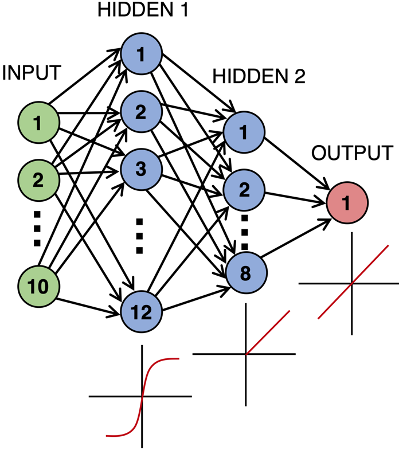

Using column vectors, the full forward pass is

$$\mathbf h_1=\tanh(W_1\mathbf x+\mathbf b_1), \quad
\mathbf h_2=\mathrm{ReLU}(W_2\mathbf h_1+\mathbf b_2),\quad
\hat{\mathbf y}=W_3\mathbf h_2+\mathbf b_3.$$

The dimensions are $W_1:12\times10$, $b_1:12$, $W_2:8\times12$, $b_2:8$, $W_3:2\times8$, $b_3:2$. The model therefore has $120+12+96+8+16+2=254$ trainable parameters. This is large relative to only 30 labeled molecules: regularization and restraint in interpreting predictions matter.

In [ ]:
# A two-feature neuron calculated by hand and by NumPy
x_demo = np.array([2.0,-1.0]); w_demo = np.array([0.5,0.25]); b_demo = 0.1
z_demo = np.dot(w_demo,x_demo)+b_demo
print('Weighted sum:',z_demo,'ReLU output:',max(0,z_demo))
assert np.isclose(z_demo,0.85)

# A tiny 2x2 layer illustrates matrix multiplication: two neurons at once.
W_demo = np.array([[0.5,0.25],[-0.2,0.8]])
b_demo_vector = np.array([0.1,-0.1])
print('Two-neuron weighted sums:',W_demo @ x_demo + b_demo_vector)


Weighted sum: 0.85 ReLU output: 0.85
Two-neuron weighted sums: [ 0.85 -1.3 ]


### Student task 2 — neural-network math (20 points)

**2A (7 pt):** Compute \(z\) for a neuron with \(x=(1,2)\), \(w=(0.3,-0.4)\), and \(b=0.2\). Give both tanh and ReLU outputs (numerically, to three decimals).

**2B (5 pt):** Explain what changes when a bias is added and why nonlinear activations matter.

**2C (5 pt):** Identify all six weight/bias array shapes for the 10–12–8–2 model. Reproduce the total parameter count.

**2D (3 pt):** Explain why a two-output neural network is appropriate for simultaneously learning the orbital energy and the energy gap.

**Your response:**

> 2A: ...  
> 2B: ...  
> 2C: ...  
> 2D: ...

## Part 3. Preparing trustworthy train/validation/test data

The original files contain a **30-molecule labeled training set** and **120 held-out molecules**. We further split the 30 into a small training portion and a **validation** portion. Validation allows us to choose stopping time or hyperparameters without inspecting the final test set.

**Standardization:** a feature measured on a much larger numerical scale can dominate early optimization. For each feature \(j\), transform \(x'_j=(x_j-\mu_j)/s_j\), where the mean and standard deviation are calculated *using the training subset only*. Apply the same \(\mu_j,s_j\) to validation and test; do not refit them on test molecules.

Because there are only 30 labeled examples, any single validation split is noisy. We will fix a seed to make the exercise reproducible and discuss sensitivity later. Here we predict two outputs in their original units but optionally scale their training targets to stabilize learning; the inverse transform is needed to report energies in eV.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X30=train_raw[:,1:11]; y30=train_raw[:,11:13]
X_test_raw=test_raw[:,1:11]; y_test=test_raw[:,11:13] # FOR FINAL EVALUATION ONLY
ids_test=test_raw[:,0].astype(int)
ix_fit,ix_val=train_test_split(np.arange(len(X30)),test_size=0.2,random_state=42)
X_fit_raw,X_val_raw=X30[ix_fit],X30[ix_val]
y_fit_raw,y_val_raw=y30[ix_fit],y30[ix_val]
x_scaler=StandardScaler().fit(X_fit_raw)
y_scaler=StandardScaler().fit(y_fit_raw)
X_fit=x_scaler.transform(X_fit_raw).astype('float32')
X_val=x_scaler.transform(X_val_raw).astype('float32')
y_fit=y_scaler.transform(y_fit_raw).astype('float32')
y_val=y_scaler.transform(y_val_raw).astype('float32')
X_test=x_scaler.transform(X_test_raw).astype('float32')
print('Development training examples:',len(X_fit),'Validation examples:',len(X_val))
print('First standardized feature mean (training):',X_fit[:,0].mean().round(4))


Development training examples: 24 Validation examples: 6
First standardized feature mean (training): 0.0


## Part 4. Training: predictions, loss, gradients and epochs

A neural network begins with randomly initialized weights. For each training molecule, it computes a prediction by passing its descriptors through each layer (**forward pass**). We compare predicted and reference energies with **mean squared error (MSE)**:

\[\mathrm{MSE}=\frac{1}{2N}\sum_{i=1}^N\sum_{k=1}^{2}(\hat y_{ik}-y_{ik})^2.\]

Here the factor 2 in the denominator counts the two output quantities; MSE gives larger penalties to larger errors. **Backpropagation** computes how changing each parameter would change the loss using the chain rule from calculus. An **optimizer** (Adam here) updates weights to reduce the loss. An **epoch** is one pass through the training examples; a **batch** is the smaller subset used for one update. An excessive number of epochs can **overfit** the training examples: training loss falls while validation loss rises.

PyTorch is used below instead of the original older Keras script, keeping its architecture and Adam optimizer while making the training mechanics explicit. We train on scaled targets for numerical convenience but report results in eV.

Selected epoch (minimum validation loss): 301


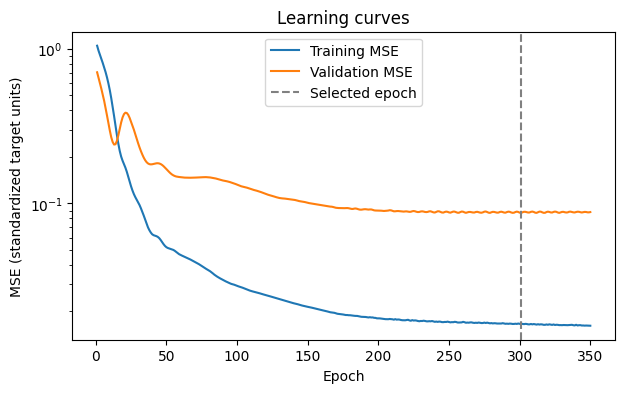

In [ ]:
import torch
from torch import nn

torch.set_num_threads(1)
def make_model(seed=42):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(10,12),nn.Tanh(),nn.Linear(12,8),nn.ReLU(),nn.Linear(8,2))

def train_network(seed=42,epochs=350,learning_rate=0.01,weight_decay=0.01):
    net=make_model(seed)
    optimizer=torch.optim.Adam(net.parameters(),lr=learning_rate,weight_decay=weight_decay)
    loss_function=nn.MSELoss()
    xx=torch.tensor(X_fit); yy=torch.tensor(y_fit)
    xv=torch.tensor(X_val); yv=torch.tensor(y_val)
    history={'epoch':[],'train_loss':[],'val_loss':[]}
    best_val=float('inf'); best_state=None; best_epoch=0
    for epoch in range(1,epochs+1):
        net.train(); optimizer.zero_grad()
        loss=loss_function(net(xx),yy)
        loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            vloss=loss_function(net(xv),yv).item()
        history['epoch'].append(epoch)
        history['train_loss'].append(loss.item())
        history['val_loss'].append(vloss)
        if vloss < best_val:
            best_val=vloss;best_epoch=epoch
            best_state={k:v.detach().clone() for k,v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net,pd.DataFrame(history),best_epoch

model,history,best_epoch=train_network()
print('Selected epoch (minimum validation loss):',best_epoch)
plt.figure(figsize=(7,4));plt.plot(history.epoch,history.train_loss,label='Training MSE')
plt.plot(history.epoch,history.val_loss,label='Validation MSE')
plt.axvline(best_epoch,color='gray',linestyle='--',label='Selected epoch')
plt.xlabel('Epoch');plt.ylabel('MSE (standardized target units)');plt.yscale('log')
plt.legend();plt.title('Learning curves');plt.show()


### Student task 3 — learning curves (20 points)

**3A (5 pt):** Define epoch, batch, loss function and optimizer in your own words.

**3B (7 pt):** Include a labeled learning-curve plot. Report the epoch selected by minimum validation error. Describe evidence for or against overfitting.

**3C (8 pt):** Experiment with a second learning rate (e.g., `learning_rate=0.001`) while keeping the split fixed. Plot or compare the curves and explain which learning rate learns faster and whether the final validation loss changes. **Do not use test results to choose the learning rate.**

**Your response:**

> 3A: ...  
> 3B: ...  
> 3C: ...

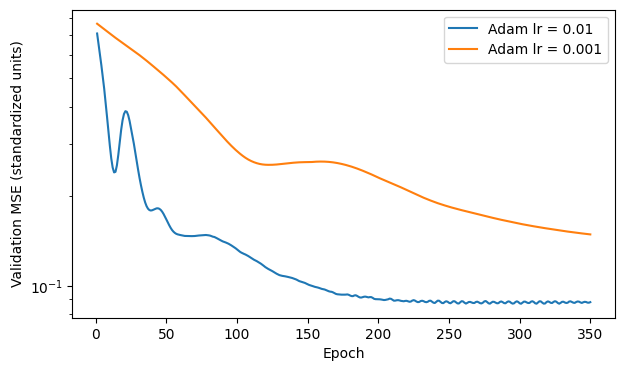

Selected epochs: 301 350


In [ ]:
# Guided experiment (students can change the learning rate).
model_slow,history_slow,selected_slow=train_network(learning_rate=0.001)
plt.figure(figsize=(7,4))
plt.plot(history.epoch,history.val_loss,label='Adam lr = 0.01')
plt.plot(history_slow.epoch,history_slow.val_loss,label='Adam lr = 0.001')
plt.xlabel('Epoch');plt.ylabel('Validation MSE (standardized units)')
plt.yscale('log');plt.legend();plt.show()
print('Selected epochs:',best_epoch,selected_slow)


## Part 5. Evaluation on unseen molecules

**MAE** is the average magnitude of prediction errors: \(\mathrm{MAE}=\langle|\hat y-y|\rangle\). **RMSE** is the square root of average squared errors and weights large mistakes more strongly. **R²** compares residual errors with a mean-prediction reference; values can be negative. In a **parity plot**, each point compares a prediction with its computed reference; perfect predictions lie along \(y=x\).

A neural network should be compared to a **simple baseline**. Linear regression uses \(\hat{y}=\beta_0+\sum_j\beta_jx_j\) and cannot naturally learn arbitrary nonlinear feature interactions. With only 24 fitting examples, a neural network is not guaranteed to beat it. We use Ridge regression (a regularized linear baseline) and train it on the *same* development subset.

**Methodology warning:** a lower test error does not automatically mean the network has learned causal chemistry; dataset design, descriptor coverage and closely related molecules also matter.

,model,target,MAE_eV,RMSE_eV,R2
0,Neural network,dxy_eV,0.0486,0.0593,0.9881
1,Neural network,gap_eV,0.0931,0.1129,0.9183
2,Ridge baseline,dxy_eV,0.0423,0.0542,0.9901
3,Ridge baseline,gap_eV,0.0885,0.1039,0.9309


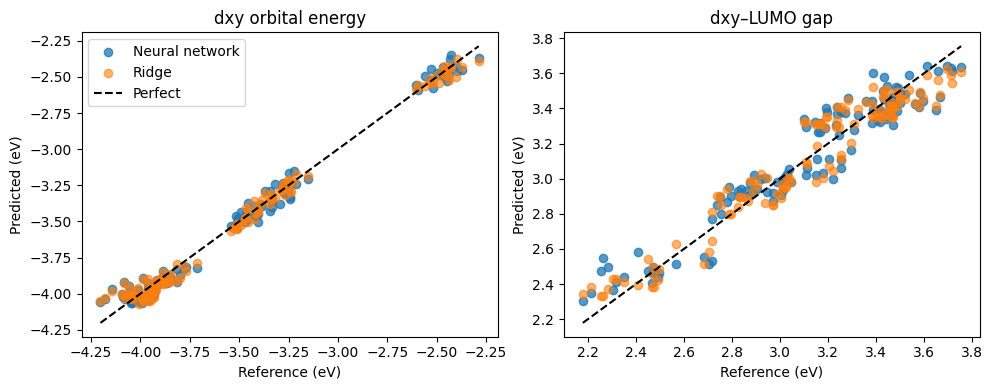

In [ ]:
from sklearn.linear_model import Ridge

def predict_ev(net,X):
    net.eval()
    with torch.no_grad():
        ys=net(torch.tensor(X,dtype=torch.float32)).numpy()
    return y_scaler.inverse_transform(ys)

# The following cell is the one-time held-out assessment of the predefined models.
net_pred=predict_ev(model,X_test)
ridge=Ridge(alpha=1.0).fit(X_fit,y_fit_raw)
ridge_pred=ridge.predict(X_test)

def metrics_frame(y,models):
    rows=[]
    for name,preds in models.items():
        for j,target in enumerate(['dxy_eV','gap_eV']):
            rows.append({'model':name,'target':target,
                         'MAE_eV':mean_absolute_error(y[:,j],preds[:,j]),
                         'RMSE_eV':np.sqrt(mean_squared_error(y[:,j],preds[:,j])),
                         'R2':r2_score(y[:,j],preds[:,j])})
    return pd.DataFrame(rows)
results=metrics_frame(y_test,{'Neural network':net_pred,'Ridge baseline':ridge_pred})
display(results.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for j,ax in enumerate(axes):
    ax.scatter(y_test[:,j],net_pred[:,j],alpha=0.75,label='Neural network')
    ax.scatter(y_test[:,j],ridge_pred[:,j],alpha=0.6,label='Ridge')
    low=min(y_test[:,j].min(),net_pred[:,j].min(),ridge_pred[:,j].min())
    high=max(y_test[:,j].max(),net_pred[:,j].max(),ridge_pred[:,j].max())
    ax.plot([low,high],[low,high],'k--',label='Perfect')
    ax.set(xlabel='Reference (eV)',ylabel='Predicted (eV)',title=['dxy orbital energy','dxy–LUMO gap'][j])
axes[0].legend();plt.tight_layout();plt.show()


### Student task 4 — evaluate and compare (20 points)

**4A (8 pt):** Submit the metric table and parity plots for both outputs (axes in eV). Which errors are largest?

**4B (7 pt):** Compare the neural network with Ridge for each output. Did extra model complexity help on this split? Why might either model perform better?

**4C (5 pt):** Explain why it is inappropriate to search hyperparameters repeatedly on the 120 labeled test molecules. Distinguish validation error from test error.

**Your response:**

> 4A: ...  
> 4B: ...  
> 4C: ...

## Part 6. Repeated models and molecular screening

The original assignment averaged predictions across 30 independently initialized neural networks. This is an **ensemble**: random initial weights can produce slightly different fits. A mean prediction may be more stable than one fit. The standard deviation across runs is **not** a calibrated predictive confidence interval; models trained on almost identical data can agree and all be wrong. Here use three seeds as a short, classroom-friendly demonstration; increasing to 30 is optional.

**Important:** Averaging predictions \(\frac1M\sum_m f_m(x)\) is not equivalent to averaging parameter tensors and then computing \(f_{\mathrm{mean}\,\theta}(x)\) for nonlinear networks.

,molecule_id,predicted_dxy_eV,run_sd_eV
99,514,-2.4031,0.0508
98,513,-2.4152,0.0467
27,215,-2.4231,0.0401
25,213,-2.4493,0.0236
26,214,-2.4509,0.0155
3,115,-2.4577,0.0296
97,512,-2.4671,0.0289
96,511,-2.4676,0.0322
2,114,-2.4753,0.0247
1,113,-2.4795,0.0156


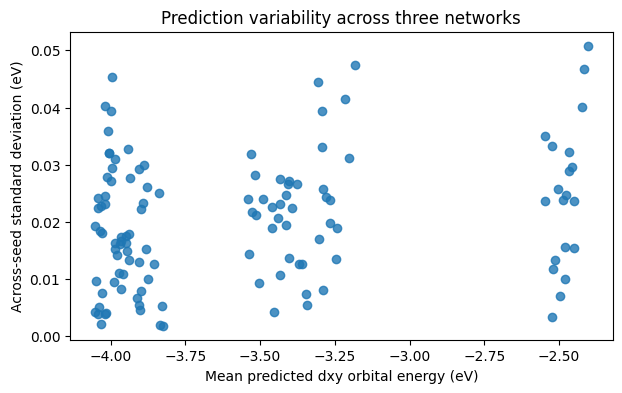

In [ ]:
seed_values=[3,17,42]  # Increase to 30 seeds for a more extensive run.
ensemble=[]
for seed in seed_values:
    net,_,selected=train_network(seed=seed)
    ensemble.append(predict_ev(net,X_test))
ensemble=np.stack(ensemble)
mean_pred=ensemble.mean(axis=0)
sd_pred=ensemble.std(axis=0,ddof=1)
ranking=pd.DataFrame({'molecule_id':ids_test,'predicted_dxy_eV':mean_pred[:,0],
                      'run_sd_eV':sd_pred[:,0]})
ranking=ranking.sort_values('predicted_dxy_eV',ascending=False)
display(ranking.head(10).round(4))
plt.figure(figsize=(7,4));plt.scatter(mean_pred[:,0],sd_pred[:,0],alpha=0.8)
plt.xlabel('Mean predicted dxy orbital energy (eV)')
plt.ylabel('Across-seed standard deviation (eV)')
plt.title('Prediction variability across three networks');plt.show()


### Student task 5 — sensitivity and screening (15 points)

**5A (5 pt):** Provide a table with the top five candidate IDs ranked by *predicted* \(d_{xy}\) energy and their across-seed SD.

**5B (5 pt):** Explain what a high across-seed SD might suggest and why a low SD does not prove accuracy.

**5C (5 pt):** Propose a reasonable computational follow-up strategy for choosing candidates from the high-ranking group for additional DFT verification. Discuss chemical feasibility and model extrapolation.

**Your response:**

> 5A: ...  
> 5B: ...  
> 5C: ...

## Part 7. Extracting a physical scoring function from a trained network

The network is an explicit mathematical function, not a black box in the sense that its predictions cannot be reproduced. Each `nn.Linear` layer stores a weight matrix and bias vector. PyTorch uses the `output = input @ weight.T + bias` convention when inputs are batches of row vectors. In the column-vector equations above, the weight arrays already have the desired dimensions.

**Important scaling detail:** Our model uses standardized descriptors and targets. To calculate a new molecule’s orbital energies manually, first standardize its ten descriptors using the training-set means/SD, perform the three matrix operations, then inverse-transform the two predicted standardized targets to eV.

![Neural network equation](attachment:equation.png)

In [ ]:
# Verify the forward-pass calculation against the network output, in eV.
net=model
layers=[layer for layer in net if isinstance(layer,nn.Linear)]
assert [(l.out_features,l.in_features) for l in layers]==[(12,10),(8,12),(2,8)]
W1,b1=[p.detach().numpy() for p in (layers[0].weight,layers[0].bias)]
W2,b2=[p.detach().numpy() for p in (layers[1].weight,layers[1].bias)]
W3,b3=[p.detach().numpy() for p in (layers[2].weight,layers[2].bias)]
x0=X_test[0]
h1=np.tanh(W1@x0+b1)
h2=np.maximum(0,W2@h1+b2)
manual_scaled=W3@h2+b3
manual_ev=y_scaler.inverse_transform(manual_scaled.reshape(1,-1))[0]
model_ev=predict_ev(net,X_test[:1])[0]
print('Manual output (eV):',manual_ev,'Network output (eV):',model_ev)
np.testing.assert_allclose(manual_ev,model_ev,rtol=1e-5,atol=1e-5)
print('All dimensions:',W1.shape,b1.shape,W2.shape,b2.shape,W3.shape,b3.shape)


Manual output (eV): [-2.559209   2.3677275] Network output (eV): [-2.559209   2.3677275]
All dimensions: (12, 10) (12,) (8, 12) (8,) (2, 8) (2,)


### Student task 6 — interpretation and transfer (10 points)

**6A (5 pt):** Explain the manual forward-pass calculation above, including where tanh, ReLU, the biases, and inverse target scaling occur. Why do the manual and PyTorch predictions agree? Why must weight arrays from independently trained networks **not** simply be averaged as if they were predictions?

**6B (5 pt):** Propose a new chemical regression problem: name an input representation, the target property and its units, where labels would come from, and an appropriate validation strategy.

**Your response:**

> 6A: ...  
> 6B: ...

## Final submission checklist

- [ ] All code cells run top-to-bottom without errors in Colab.
- [ ] Responses to tasks 1–6 are written in complete sentences.
- [ ] Plots have titles, axes, and physical units where relevant.
- [ ] Your work clearly distinguishes training, validation and held-out testing.
- [ ] You report both output properties rather than only one.
- [ ] You explain limitations of Hammett-style descriptors and of a 30-example dataset.

**Instructor note:** The original homework included optional questions about Welch's unequal-variance t-test and hyperparameter search. These are valuable extensions, but a t-test on feature averages alone cannot certify training-set representativeness or reliable extrapolation. Advanced students can optionally implement repeated group-aware splits, learning curves against training-set size, or uncertainty calibration. Do not use the held-out test data for such design decisions.

**Provenance:** Adapted from the uploaded `Leitner_Assignment_1_NeuralNetworks.ipynb`, `HammettNNTrain.csv`, `HammettNNTest.csv`, `HammettNN150.csv`, and chemical/network images. The accompanying legacy `HammettNNModelExtraction.py` uses older Keras conventions and an unavailable `tungsten4.csv` filename; this notebook replaces the inaccessible path with reproducible extraction from the trained PyTorch network.